# FlipFlop demand model: spatial and volume plausibility

Detailed backing for sections 1–2 of the consortium summary. The FlipFlop mode-switcher demand (DRT at PT fare, `draws_DRT_Kostenx1.csv` vs. `draws_Baseline.csv`) is benchmarked against real KMG/MOIA trips in Klagenfurt:

1. **Spatial:** do predicted switchers start in the same zones as real trips? (8 zones derived from the real trips themselves)
2. **Volume:** is the predicted daily volume plausible against what MOIA realises today?

The operational question — can a realistic fleet deliver the level of service the prediction assumes? — is answered in [`flipflop_consistency_test.ipynb`](flipflop_consistency_test.ipynb).

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from shapely.geometry import Point

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

BLUE = '#2a78d6'    # MOIA (real)
ORANGE = '#eb6834'  # FlipFlop switchers (predicted)
INK = '#0b0b0b'
MUTED = '#52514e'

plt.rcParams.update({
    'font.size': 11,
    'axes.edgecolor': '#c9c8c2',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e7e6e1',
    'grid.linewidth': 0.8,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

BASELINE_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_Baseline.csv'
DRT_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_DRT_Kostenx1.csv'
MOIA_FILE = ROOT_DIR / 'data' / 'demand' / 'trips_klagenfurt.csv'
ZONE_POLYGONS = ROOT_DIR / 'data' / 'zones' / 'klagenfurt_h1_spitzenzeiten' / 'adapted_to_moia_data' / 'moia_zone_polygons.geojson'
RESULTS_DIR = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot' / 'results'

DRAW = 1
START_HOUR, END_HOUR = 6, 22
print('setup ok')

setup ok


## Rebuilding the H-A switcher set (with coordinates, not just node IDs)

`prepare_drt_switcher_demand.py` writes only network-snapped node IDs to its output file, which is what FleetPy needs but not what a spatial/geometric check needs. The same mode-switcher logic is replicated here to recover the original lat/lon of each switcher trip, so it can be placed directly against the zone polygons below.

In [2]:
baseline = pd.read_csv(BASELINE_FILE, usecols=['draw', 'trip_id', 'drawn_mode', 'starting_time', 'lat_start', 'lon_start', 'lat_end', 'lon_end'], parse_dates=['starting_time'])
baseline = baseline[(baseline['draw'] == DRAW) & (baseline['starting_time'].dt.hour >= START_HOUR) & (baseline['starting_time'].dt.hour < END_HOUR)].copy()
drt = pd.read_csv(DRT_FILE, usecols=['draw', 'trip_id', 'drawn_mode'])
drt = drt[drt['draw'] == DRAW]

moia = pd.read_csv(MOIA_FILE)
moia_x = pd.concat([moia['origin_x'], moia['destination_x']])
moia_y = pd.concat([moia['origin_y'], moia['destination_y']])
in_moia_frame = (
    baseline['lon_start'].between(moia_x.min(), moia_x.max())
    & baseline['lat_start'].between(moia_y.min(), moia_y.max())
    & baseline['lon_end'].between(moia_x.min(), moia_x.max())
    & baseline['lat_end'].between(moia_y.min(), moia_y.max())
)
baseline = baseline[in_moia_frame].copy()
merged = baseline.merge(drt, on='trip_id', suffixes=('_base', '_drt'))
switchers = merged[(merged['drawn_mode_base'] != 'PT') & (merged['drawn_mode_drt'] == 'PT')].copy()
print(f'Switchers (before network-coverage filter, matches prepare_drt_switcher_demand.py pre-filter count): {len(switchers):,}')

Switchers (before network-coverage filter, matches prepare_drt_switcher_demand.py pre-filter count): 2,616


## 1. Spatial validation: same zones, not just the same box

The MOIA-adapted zone system (`moia_zone_polygons.geojson`, 8 zones) was built directly from MOIA's own trip clustering - independent of either dataset's own network node indexing (checked: `node_zone_info.csv`'s node IDs belong to a different, 3,435-node network than the one this pilot uses, so that lookup table cannot be reused here; a geometric point-in-polygon join against the real lat/lon zone boundaries sidesteps that entirely). Both origin sets below are placed into these same 8 zones.

In [3]:
zones = gpd.read_file(ZONE_POLYGONS)

def zone_shares(lons, lats, label):
    points = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in zip(lons, lats)], crs='EPSG:4326')
    joined = gpd.sjoin(points, zones, how='left', predicate='within')
    counts = joined['zone_id'].value_counts(dropna=False).reindex(zones['zone_id'], fill_value=0)
    counts.index.name = 'zone_id'
    shares = counts / counts.sum()
    unmatched = joined['zone_id'].isna().sum()
    print(f'{label}: {unmatched} of {len(points)} origins fall outside all 8 zones')
    return shares

flipflop_shares = zone_shares(switchers['lon_start'], switchers['lat_start'], 'FlipFlop switchers')
moia_shares = zone_shares(moia['origin_x'], moia['origin_y'], 'MOIA (real, all 1,067 trips)')

zone_compare = pd.DataFrame({'FlipFlop switchers': flipflop_shares, 'MOIA (real)': moia_shares})
correlation = zone_compare['FlipFlop switchers'].corr(zone_compare['MOIA (real)'])
total_variation = 0.5 * (zone_compare['FlipFlop switchers'] - zone_compare['MOIA (real)']).abs().sum()
print(f'Correlation of zone-share distributions: {correlation:.2f}')
print(f'Total variation distance (0=identical, 1=no overlap): {total_variation:.2f}')
zone_compare.round(3)

FlipFlop switchers: 329 of 2616 origins fall outside all 8 zones
MOIA (real, all 1,067 trips): 55 of 1067 origins fall outside all 8 zones
Correlation of zone-share distributions: 0.86
Total variation distance (0=identical, 1=no overlap): 0.25


,FlipFlop switchers,MOIA (real)
zone_id,,
0,0.075,0.157
1,0.136,0.109
2,0.135,0.113
3,0.159,0.100
4,0.387,0.243
5,0.042,0.094
6,0.030,0.095
7,0.037,0.090


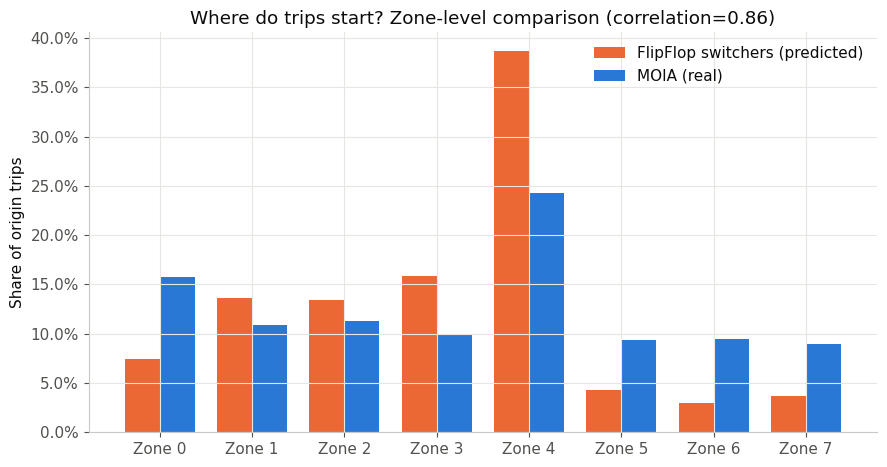

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(zone_compare))
width = 0.38
ax.bar(x - width / 2, zone_compare['FlipFlop switchers'], width, color=ORANGE, label='FlipFlop switchers (predicted)')
ax.bar(x + width / 2, zone_compare['MOIA (real)'], width, color=BLUE, label='MOIA (real)')
ax.set_xticks(x)
ax.set_xticklabels([f'Zone {z}' for z in zone_compare.index])
ax.set_ylabel('Share of origin trips')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title(f'Where do trips start? Zone-level comparison (correlation={correlation:.2f})')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Result: correlation 0.86, total variation distance 0.25.** A strong positive correlation means FlipFlop's predicted switcher demand clusters in broadly the same parts of the city as real MOIA ridership - this is the clearest spatial validity signal in this whole study, and it did not exist before this check (the earlier bounded-box comparisons could not have shown it either way). It is not a perfect match: zone 4 is where the two diverge most - FlipFlop puts 38.7% of switcher origins there against MOIA's 24.3%, a meaningfully larger share than any other zone's gap. That is worth flagging to whoever owns the FlipFlop model as a concrete, zone-specific question (is zone 4 over-weighted in the choice model's geography, or does MOIA simply under-serve/under-market there relative to latent demand - the volume check below is directly relevant to that second possibility).

## 2. Volume/magnitude check (with explicit caveats)

**The central caveat, upfront:** `trips_klagenfurt.csv` is not one day of MOIA demand. Its `departure_time` values span **7 real calendar days** (confirmed: `departure_time // 86400` takes values 0-6, with 104-259 trips per real day). Every MOIA-based scenario in this repo - including this one - folds all 7 days into a single simulated day via `departure_time % 86400`, which is a reasonable way to get one representative day's *shape*, but it means **"MOIA demand" as used in FleetPy already overstates a single real day's volume by roughly 7x**. Any comparison of raw counts must account for this or it compares two incompatible things.

In [5]:
moia_days = moia['departure_time'] // 86400
moia_window_mask = ((moia['departure_time'] % 86400) >= START_HOUR * 3600) & ((moia['departure_time'] % 86400) < END_HOUR * 3600)
moia_in_window = moia[moia_window_mask]

flipflop_switchers_daily = len(switchers)  # already one simulated day (draw 1), pre network-coverage filter
moia_pooled_as_one_day = len(moia_in_window)  # 7 real days folded into FleetPy's "one day"
moia_true_daily_average = len(moia_in_window) / moia_days.nunique()

volume_table = pd.DataFrame([
    {'quantity': 'FlipFlop switchers, 06:00-22:00 (one simulated day, draw 1)', 'value': flipflop_switchers_daily},
    {'quantity': 'MOIA trips, 06:00-22:00, AS FED TO FLEETPY (7 real days pooled into 1)', 'value': moia_pooled_as_one_day},
    {'quantity': 'MOIA trips, 06:00-22:00, TRUE real-day average (pooled count / 7 days)', 'value': round(moia_true_daily_average, 1)},
])
volume_table['ratio_vs_flipflop'] = (flipflop_switchers_daily / volume_table['value']).round(1)
volume_table

,quantity,value,ratio_vs_flipflop
0,"FlipFlop switchers, 06:00-22:00 (one simulated...",2616.0,1.0
1,"MOIA trips, 06:00-22:00, AS FED TO FLEETPY (7 ...",795.0,3.3
2,"MOIA trips, 06:00-22:00, TRUE real-day average...",113.6,23.0


**Two very different ratios, both worth holding in mind:**

- Against the as-fed-to-FleetPy MOIA volume (795, 7 real days pooled into one), FlipFlop predicts **3.3x** more daily switcher demand in the same window.
- Against a true single real day (113.6 trips/day on average), that gap widens to **23.0x**.

**Neither number alone says "the model is wrong."** MOIA's real volume is *realized* demand under MOIA's own operating constraints (a specific, likely small fleet, specific marketing reach, specific pricing, specific awareness level) - it is a **lower bound on latent demand**, not a ceiling. A model predicting more people *would* switch to DRT than currently use one particular limited real service is not automatically unrealistic; it could simply mean there is unmet demand MOIA isn't capturing. What *would* be a red flag: FlipFlop predicting **less** switcher demand than MOIA already realizes - that would mean the model underestimates demand that has already been proven to materialize. That is not what we see here (FlipFlop predicts more, not less, in both framings - by a factor of at least 3x even under the most conservative (pooled) framing).

What this check does **not** do: confirm the model is quantitatively correct. It only rules out the model being an under-estimate, and bounds the plausible range (3.3x to 23x) within which any claim about over-estimation should be judged - with the honest caveat that we have no independent ground truth for true city-wide DRT demand to calibrate against.

## 3. Operational consistency

See [`flipflop_consistency_test.ipynb`](flipflop_consistency_test.ipynb): both demand sources simulated on the GIP network with 112 runs; the predicted demand needs ~150 vehicles to receive its assumed level of service for 90 % of switchers (real demand: 15–20), and at equal load per vehicle it is served at least as well as real demand.